![Banner](../../../../Images/Banner/07_remote_sensing/09_11_banner_rs_foundation_models.png)

# Weather and Earth System Foundation Models

The largest foundation models in Earth science do not read satellite images at all: they read the
gridded state of the atmosphere and predict how it evolves. Since 2022 learned weather models have
matched or beaten the best physics-based forecasts at a fraction of the computing cost. This notebook
compares the main models in the catalog, then runs Microsoft's Aurora on real ERA5 reanalysis
streamed from WeatherBench2, makes 6 and 12 hour global forecasts and scores them against ERA5 and
against a persistence baseline, with a closer look at the US Corn Belt used elsewhere in this chapter.

## Overview

### From numerical weather prediction to learned emulators

Numerical weather prediction (NWP) solves the equations of the atmosphere on a grid, step by step,
on supercomputers. A learned emulator is trained on decades of **reanalysis** (ERA5: the best
estimate of the past atmosphere, hourly at 0.25 degrees since 1940) to map the state at time t to the
state at t + 6 h. Applied repeatedly (an autoregressive **rollout**) it produces a forecast in
seconds on one GPU.

| Model | Provider | Architecture | Notable for |
|---|---|---|---|
| FourCastNet | NVIDIA, 2022 | Fourier neural operator (v1), spherical FNO (v2) | first competitive learned model; very fast ensembles |
| GraphCast | Google DeepMind, 2023 | graph neural network on an icosahedral mesh | beat ECMWF HRES on most targets at 10 days |
| GenCast | Google DeepMind, 2024 | diffusion model on a mesh | probabilistic ensembles that beat ECMWF ENS |
| Aurora | Microsoft, 2024 | 3-D Swin U-Net with Perceiver encoders, 1.3 B parameters | one foundation model fine-tuned for weather, air pollution, ocean waves |
| Prithvi WxC | NASA and IBM, 2024 | 2.3 B transformer on MERRA-2 | downscaling, gravity waves, fine-tuning tasks |

Aurora is a foundation model in the full sense of this chapter: pretrained on more than a million
hours of diverse atmospheric data, then fine-tuned for tasks.

### What these models predict

Aurora reads four **surface variables** (2 m temperature, 10 m wind components, mean sea level
pressure), five **atmospheric variables** (geopotential, wind components, temperature, specific
humidity) on 13 pressure levels, three **static variables** (surface geopotential, land-sea mask,
soil type) and the two most recent states, 6 hours apart, so it sees the tendency.

### How forecasts are scored

The root mean square error (RMSE) against the verifying analysis, weighted by the cosine of latitude
so that the crowded grid cells near the poles do not dominate, is the standard score. **Persistence**
(tomorrow equals today) is the simplest baseline; any forecast must beat it.

### Links to land applications

Weather drives everything else in this chapter: crop calendars (notebook 09_11_06), drought,
evapotranspiration (chapter 08_12) and yield. Learned forecasts are fast enough to run large
ensembles for those applications.

## Weather Models with GeoLattice

| Task | Tool |
|---|---|
| catalog | `fm.list_models("weather")`, `fm.model_info` |
| ERA5 | WeatherBench2 Zarr store on Google Cloud, read anonymously with `xarray` and `gcsfs` |
| model | `aurora` package (`pip install microsoft-aurora`) |
| scores | latitude-weighted RMSE with NumPy |

### Learning objectives

1. Compare the main learned weather models and what they predict.
2. Read ERA5 from a cloud Zarr store without downloading the archive.
3. Assemble Aurora's input batch: surface, atmospheric and static variables with metadata.
4. Run a 6 hour forecast and a 12 hour rollout.
5. Score forecasts with latitude-weighted RMSE against ERA5 and persistence.

### Data

| Dataset | Content |
|---|---|
| ERA5 (WeatherBench2) | 0.25 degree, 6-hourly, 13 pressure levels; 1 January 2023, 00 UTC to 12 UTC, plus 18 UTC for verification |

### Contents

- Setup
- The weather models in the catalog
- ERA5 from the cloud
- Building an Aurora batch
- A 6 hour forecast
- Scoring against ERA5 and persistence
- A 12 hour rollout and the Corn Belt
- Summary and exercises

## Setup

Notebook 12 also needs `pip install microsoft-aurora gcsfs`. The ERA5 fields are read over the internet (about 1 GB).

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `microsoft-aurora`, `geolattice[rsense-foundation]`, which no GeoLattice option installs: `pip install microsoft-aurora "geolattice[rsense-foundation]"`.

In [1]:
import os  # environment variables
os.environ.setdefault("USE_TF", "0")  # keep transformers from loading TensorFlow
import time  # timing
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import torch  # PyTorch: every model runs on it
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.foundation_models as fm  # catalog, loaders, embeddings and probes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing")  # remote sensing data folder
IC = DATA / "09_09_image_classification"  # data shared with the image classification chapter
CAP = DATA / "08_11_Capstones"  # data shared with the capstones
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # run models on the GPU when there is one
SEED = 0  # one seed for every random step
np.random.seed(SEED)  # NumPy
torch.manual_seed(SEED)  # PyTorch

print("GeoLattice", geolattice.__version__, "| PyTorch", torch.__version__, "| device", DEVICE)  # versions used
if DEVICE == "cuda":  # name the GPU
    print("GPU:", torch.cuda.get_device_name(0))  # GPU model

from datetime import datetime  # forecast times
ERA5 = "gs://weatherbench2/datasets/era5/1959-2023_01_10-wb13-6h-1440x721_with_derived_variables.zarr"  # public Zarr store
SURF = {"2t": "2m_temperature", "10u": "10m_u_component_of_wind", "10v": "10m_v_component_of_wind",
        "msl": "mean_sea_level_pressure"}  # Aurora surface name -> ERA5 name
ATMOS = {"z": "geopotential", "u": "u_component_of_wind", "v": "v_component_of_wind", "t": "temperature",
         "q": "specific_humidity"}  # Aurora atmospheric name -> ERA5 name
STATIC = {"z": "geopotential_at_surface", "lsm": "land_sea_mask", "slt": "soil_type"}  # static variables

GeoLattice 0.3.47 | PyTorch 2.14.0+cu132 | device cuda
GPU: NVIDIA RTX A5500 Laptop GPU


## The weather models in the catalog

In [2]:
fm.list_models("weather")[["provider", "year", "params", "weights", "use_cases"]]  # the five emulators

,provider,year,params,weights,use_cases
name,,,,,
prithvi-wxc,NASA / IBM,2024,2.3B,ibm-nasa-geospatial/Prithvi-WxC-1.0-2300M,downscaling; gravity waves; forecast fine-tuning
aurora,Microsoft,2024,1.3B,microsoft/aurora (torchgeo Aurora_Weights),weather; air pollution; ocean waves
graphcast,Google DeepMind,2023,37M,github.com/google-deepmind/graphcast,10-day forecasts
gencast,Google DeepMind,2024,n/a,github.com/google-deepmind/graphcast,probabilistic ensemble forecasts
fourcastnet,NVIDIA,2022,n/a,NVIDIA earth2studio / modulus,fast forecasts; large ensembles


None of them goes through `fm.load_model`: their inputs are atmospheric states, not images, and each
has its own package. Aurora's package is installed from PyPI and downloads its checkpoint from
Hugging Face.

## ERA5 from the cloud

WeatherBench2 publishes ERA5 as a Zarr store on Google Cloud Storage. Opening it reads only the
metadata; values are fetched when needed. The forecast starts from the states at 00 and 06 UTC on
1 January 2023 and is verified at 12 and 18 UTC.

In [3]:
era = xr.open_zarr(ERA5, storage_options={"token": "anon"}, consolidated=True)  # lazy, anonymous
print(dict(era.sizes)); print("levels (hPa):", era.level.values)  # archive size and levels
times = pd.to_datetime(["2023-01-01T00", "2023-01-01T06", "2023-01-01T12", "2023-01-01T18"])  # inputs and targets
t0 = time.perf_counter()  # start the clock
state = era[list(SURF.values()) + list(ATMOS.values())].sel(time=times).load()  # about 1 GB
static = era[list(STATIC.values())].load()  # static fields
print(f"loaded in {time.perf_counter() - t0:.0f} s | lat {float(era.latitude[0])} to {float(era.latitude[-1])}")  # timing and orientation

{'time': 93544, 'latitude': 721, 'longitude': 1440, 'level': 13}
levels (hPa): [  50  100  150  200  250  300  400  500  600  700  850  925 1000]


loaded in 13 s | lat 90.0 to -90.0


## Building an Aurora batch

An Aurora `Batch` holds tensors of shape (batch, history, ...) for surface and atmospheric variables,
2-D static fields, and metadata: latitudes (decreasing), longitudes (0 to 360), the time of the latest
state and the pressure levels. The history is the 00 and 06 UTC states.

In [4]:
from aurora import Batch, Metadata  # Aurora data structures

def make_batch(i0):  # the states at times[i0] and times[i0 + 1] as an Aurora batch
    sl = slice(i0, i0 + 2)  # two consecutive states
    return Batch(
        surf_vars={k: torch.from_numpy(state[v].isel(time=sl).values[None]) for k, v in SURF.items()},  # (1, 2, lat, lon)
        static_vars={k: torch.from_numpy(static[v].values) for k, v in STATIC.items()},  # (lat, lon)
        atmos_vars={k: torch.from_numpy(state[v].isel(time=sl).values[None]) for k, v in ATMOS.items()},  # (1, 2, level, lat, lon)
        metadata=Metadata(lat=torch.from_numpy(era.latitude.values), lon=torch.from_numpy(era.longitude.values),
                          time=(times[i0 + 1].to_pydatetime(),), atmos_levels=tuple(int(l) for l in era.level.values)))  # metadata

batch = make_batch(0)  # history 00 and 06 UTC
print({k: tuple(v.shape) for k, v in batch.surf_vars.items()}, "|", {k: tuple(v.shape) for k, v in batch.atmos_vars.items()})  # shapes

{'2t': (1, 2, 721, 1440), '10u': (1, 2, 721, 1440), '10v': (1, 2, 721, 1440), 'msl': (1, 2, 721, 1440)} | {'z': (1, 2, 13, 721, 1440), 'u': (1, 2, 13, 721, 1440), 'v': (1, 2, 13, 721, 1440), 't': (1, 2, 13, 721, 1440), 'q': (1, 2, 13, 721, 1440)}


## A 6 hour forecast

The full Aurora (1.3 billion parameters, pretrained on ERA5 and other sources) needs more memory than a
16 GB GPU offers at 0.25 degrees: its weights alone take 4.8 GB, and a global forecast step on this
machine's GPU ran out of memory at about 13 GB of activations. It runs on the CPU instead, about six
minutes per step with 24 cores. On a GPU with 24 GB or more the same code runs on the GPU in seconds.
`rollout` runs two 6 hour steps at once; the first is the +6 h forecast scored here, the second the
+12 h forecast scored further down.

In [5]:
from aurora import AuroraPretrained, rollout  # model and autoregressive rollout

big_gpu = DEVICE == "cuda" and torch.cuda.get_device_properties(0).total_memory >= 24 * 2**30  # enough GPU memory?
AURORA_DEVICE = "cuda" if big_gpu else "cpu"  # where the full model runs
torch.set_num_threads(os.cpu_count())  # use every core on the CPU
model = AuroraPretrained(autocast=big_gpu)  # 1.3 B parameters (bfloat16 autocast on the GPU)
model.load_checkpoint("microsoft/aurora", "aurora-0.25-pretrained.ckpt")  # pretrained weights (about 5 GB, cached)
model = model.to(AURORA_DEVICE).eval()  # inference mode
t0 = time.perf_counter()  # start the clock
with torch.inference_mode():  # inference only
    preds = [p.to("cpu") for p in rollout(model, batch, steps=2)]  # +6 h and +12 h
pred = preds[0]  # the +6 h forecast
print(f"Aurora 0.25 pretrained on {AURORA_DEVICE}: {sum(p.numel() for p in model.parameters()) / 1e9:.2f} B parameters | "
      f"two steps in {time.perf_counter() - t0:.0f} s | first forecast valid at {pred.metadata.time[0]}")  # what ran
del model  # free memory
MODEL = "Aurora 0.25 pretrained (1.3 B)"  # label for the figures

Aurora 0.25 pretrained on cpu: 1.26 B parameters | two steps in 873 s | first forecast valid at 2023-01-01 12:00:00


## Scoring against ERA5 and persistence

The forecast valid at 12 UTC is compared with the ERA5 analysis at 12 UTC, and so is persistence (the
06 UTC state). Aurora returns a grid with 720 latitudes (it drops the south pole row), so ERA5 is cut
to match.

In [6]:
lat = pred.metadata.lat.cpu().numpy()  # forecast latitudes
w = np.cos(np.deg2rad(lat))[:, None]; w = w / w.mean()  # latitude weights
rmse = lambda a, b: float(np.sqrt(np.nanmean(w * (a - b) ** 2)))  # latitude-weighted RMSE
truth = state.sel(latitude=lat, method="nearest")  # ERA5 on the forecast grid
rows = []  # scores
for k, v in SURF.items():  # surface variables
    f = pred.surf_vars[k][0, 0].float().cpu().numpy()  # forecast
    rows.append({"variable": k, "Aurora +6 h": rmse(f, truth[v].isel(time=2).values), "persistence": rmse(truth[v].isel(time=1).values, truth[v].isel(time=2).values)})  # scores
for k, v, lev in [("z", "geopotential", 500), ("t", "temperature", 850), ("u", "u_component_of_wind", 250)]:  # upper air
    li = list(era.level.values).index(lev)  # level index
    f = pred.atmos_vars[k][0, 0, li].float().cpu().numpy()  # forecast
    rows.append({"variable": f"{k}{lev}", "Aurora +6 h": rmse(f, truth[v].isel(time=2, level=li).values),
                 "persistence": rmse(truth[v].isel(time=1, level=li).values, truth[v].isel(time=2, level=li).values)})  # scores
sc = pd.DataFrame(rows).set_index("variable"); sc["skill vs persistence"] = 1 - sc["Aurora +6 h"] / sc["persistence"]  # skill score
sc.round(3)

,Aurora +6 h,persistence,skill vs persistence
variable,,,
2t,0.491,2.824,0.826
10u,0.523,1.956,0.733
10v,0.533,2.314,0.770
msl,31.935,264.613,0.879
z500,23.999,222.807,0.892
t850,0.432,1.492,0.711
u250,1.218,4.888,0.751


Six hours ahead, Aurora's errors are a small fraction of persistence's for every variable: 0.49 K
against 2.8 K for 2 m temperature, 32 Pa against 265 Pa for sea level pressure, 24 m2 s-2 against 223
for 500 hPa geopotential. The skill score (1 minus the ratio of the two errors) ranges from about 0.71
for 850 hPa temperature to 0.89 for 500 hPa geopotential. Persistence is a weak baseline at 6 hours,
because the daily cycle alone moves surface temperature by several kelvin; the point is that the
learned model captures that cycle and the moving weather systems from two input states.

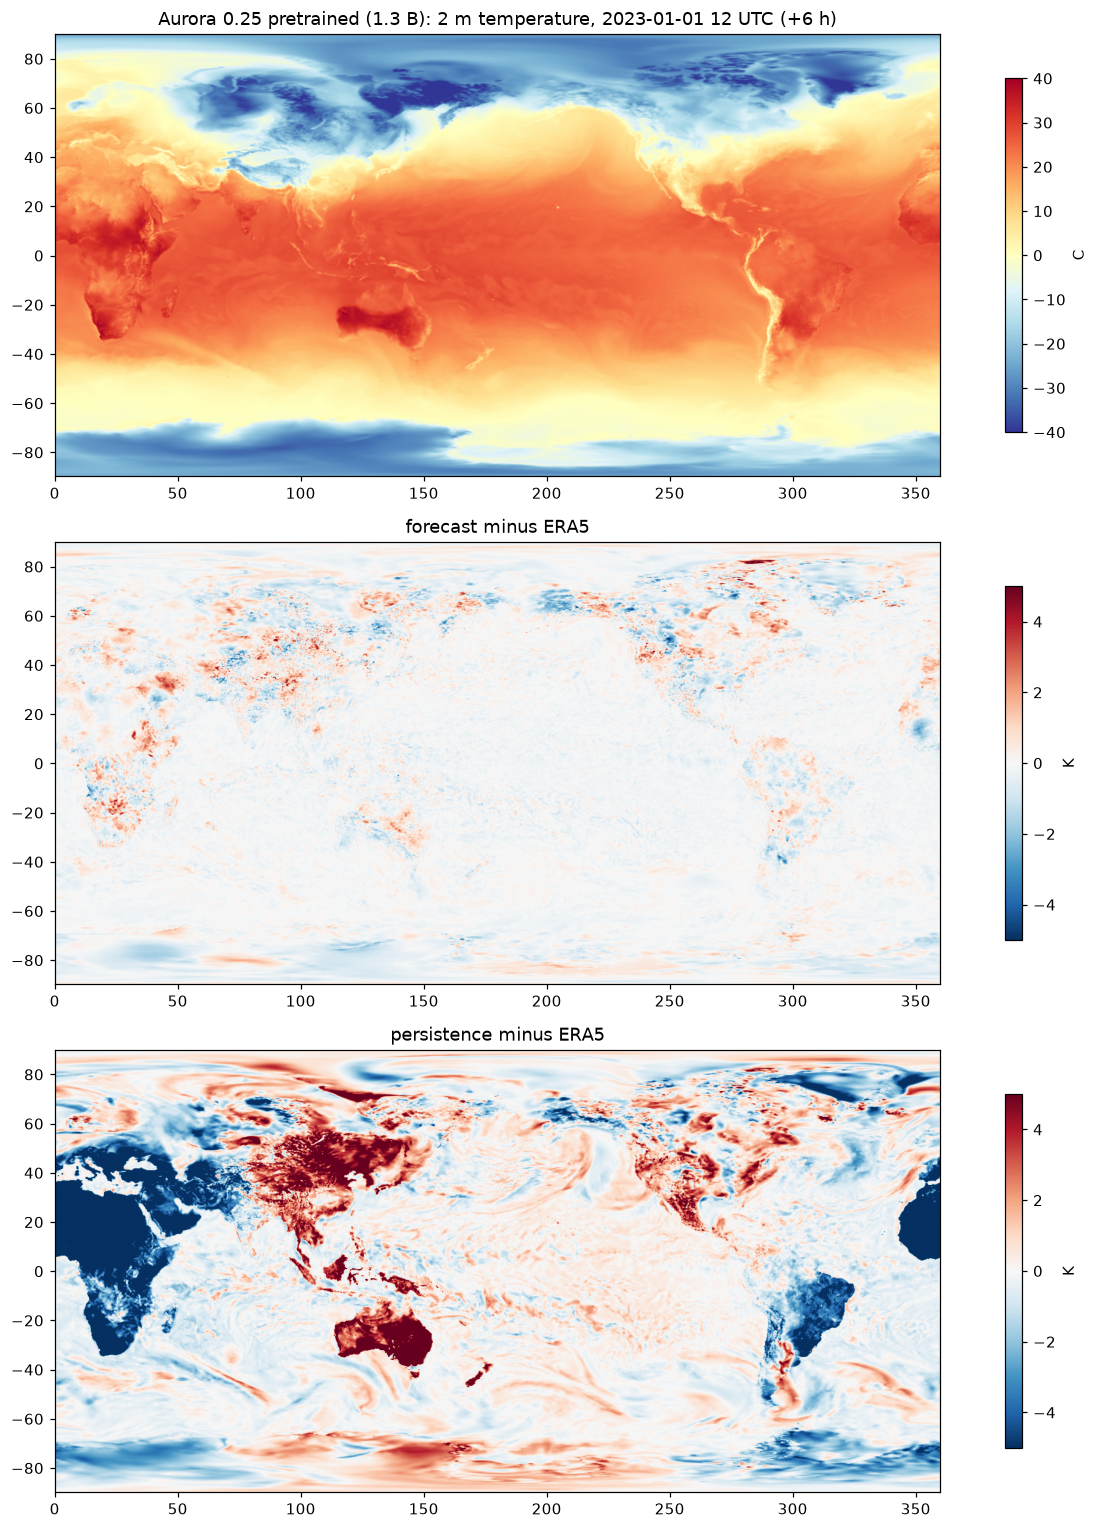

In [7]:
f2t = pred.surf_vars["2t"][0, 0].float().cpu().numpy() - 273.15  # forecast 2 m temperature (C)
err = f2t - (truth["2m_temperature"].isel(time=2).values - 273.15)  # forecast minus ERA5
pers = (truth["2m_temperature"].isel(time=1).values - truth["2m_temperature"].isel(time=2).values)  # persistence error
ext = [0, 360, float(lat[-1]), float(lat[0])]  # map extent
fig, ax = plt.subplots(3, 1, figsize=(12, 14))  # three maps
im = ax[0].imshow(f2t, cmap="RdYlBu_r", vmin=-40, vmax=40, extent=ext); ax[0].set_title(f"{MODEL}: 2 m temperature, 2023-01-01 12 UTC (+6 h)"); plt.colorbar(im, ax=ax[0], shrink=0.8, label="C")  # forecast
im = ax[1].imshow(err, cmap="RdBu_r", vmin=-5, vmax=5, extent=ext); ax[1].set_title("forecast minus ERA5"); plt.colorbar(im, ax=ax[1], shrink=0.8, label="K")  # error
im = ax[2].imshow(pers, cmap="RdBu_r", vmin=-5, vmax=5, extent=ext); ax[2].set_title("persistence minus ERA5"); plt.colorbar(im, ax=ax[2], shrink=0.8, label="K")  # baseline error
plt.tight_layout(); plt.show()  # draw

The persistence error map is dominated by the daily cycle: between 06 and 12 UTC the sun rises over
Africa and Europe (cold errors there, since persistence keeps the night) and sets over East Asia and
Australia (warm errors). Aurora's error map has none of that pattern. What remains is small-scale noise
over land, largest over mountains, deserts and the high latitudes of the northern winter, where surface
temperature varies over short distances, and a near-zero error over the oceans.

## A 12 hour rollout and the Corn Belt

`aurora.rollout` fed the first forecast back as input, so its second step is a forecast valid at
18 UTC, 12 hours after the last input. The score is computed for the globe and for a box over Iowa
(40 to 45 N, 97 to 90 W), the Corn Belt study area of this chapter.

In [8]:
box = (lat >= 40) & (lat <= 45)  # Iowa latitudes
lon = pred.metadata.lon.cpu().numpy(); lbox = (lon >= 263) & (lon <= 270)  # 97 to 90 W in 0..360
rows = []  # rollout scores
for step, p in enumerate(preds, 1):  # each lead time
    f = p.surf_vars["2t"][0, 0].float().numpy()  # forecast
    tgt = truth["2m_temperature"].isel(time=1 + step).values  # ERA5 at the valid time
    per = truth["2m_temperature"].isel(time=1).values  # persistence from 06 UTC
    rows.append({"lead (h)": 6 * step, "Aurora global": rmse(f, tgt), "persistence global": rmse(per, tgt),
                 "Aurora Iowa": float(np.sqrt(np.mean((f - tgt)[np.ix_(box, lbox)] ** 2))),
                 "persistence Iowa": float(np.sqrt(np.mean((per - tgt)[np.ix_(box, lbox)] ** 2)))})  # scores
pd.DataFrame(rows).set_index("lead (h)").round(2)  # 2 m temperature RMSE (K)

,Aurora global,persistence global,Aurora Iowa,persistence Iowa
lead (h),,,,
6,0.49,2.82,0.79,3.59
12,0.61,3.25,1.43,3.35


Errors grow with lead time, from 0.49 K to 0.61 K globally between 6 and 12 hours, still a fifth of
persistence's error. Over Iowa the errors are larger (0.8 K at 6 hours, 1.4 K at 12 hours): a small,
continental, winter region with snow and strong night-time cooling is harder than the global average,
which is dominated by oceans. A score over the region of interest, not only the global one, is what
an application needs.

## Summary and exercises

### Summary

- Learned weather models (FourCastNet, GraphCast, GenCast, Aurora, Prithvi WxC) emulate the
  atmosphere from reanalysis and forecast in seconds on one GPU.
- ERA5 can be read directly from the WeatherBench2 Zarr store, field by field, without downloading the
  archive.
- Aurora takes surface, atmospheric and static variables with their metadata as a `Batch`, and
  `rollout` produces forecasts at longer lead times.
- Forecasts are scored with latitude-weighted RMSE against the verifying analysis, and must beat
  persistence; the skill score shows by how much.

### Exercises

1. Extend the rollout to 4 steps (24 hours) and plot RMSE against lead time for Aurora and persistence.
2. Score the 500 hPa geopotential (z500) of the rollout, the classic medium-range target.
3. Start the forecast on 1 July 2022 instead. Is the error over Iowa in summer larger or smaller?
4. Read the Aurora air-pollution or wave model cards in its documentation and list the extra inputs
   each needs.
5. Compute daily maximum 2 m temperature over Iowa from a four-step rollout, the quantity a crop
   model would use.

### References

- Bi, K. et al. (2023). Accurate medium-range global weather forecasting with 3D neural networks (Pangu-Weather). Nature.
- Bodnar, C. et al. (2025). A foundation model for the Earth system (Aurora). Nature.
- Hersbach, H. et al. (2020). The ERA5 global reanalysis. Quarterly Journal of the Royal Meteorological Society.
- Lam, R. et al. (2023). Learning skillful medium-range global weather forecasting (GraphCast). Science.
- Pathak, J. et al. (2022). FourCastNet. arXiv:2202.11214.
- Price, I. et al. (2025). Probabilistic weather forecasting with machine learning (GenCast). Nature.
- Rasp, S. et al. (2024). WeatherBench 2: a benchmark for the next generation of data-driven global weather models. JAMES.
- Schmude, J. et al. (2024). Prithvi WxC: foundation model for weather and climate. arXiv:2409.13598.